# Proyecto -- Timeseries Forecasting
## M3-BEDU

- **Objetivo**: De una serie de tiempo, en este caso las ventas de un negocio, haremos predicciones a futuro sólo *en base a tendencias y periodicidad histórica* (métodos auto-regresivos).

- **Herramientas**: Usaremos principalmente StatModels y sus distintas librerías para análisis, modelación y automatización de la predicción de series de tiempo.

- **Basado en**:
https://towardsdatascience.com/predict-time-stamped-sales-in-python-1914292461ad
https://github.com/srees1988/sarima-in-py/blob/master/SARIMA.ipynb

- **Dataset**: De Kaggle via
https://github.com/srees1988/sarima-in-py/blob/master/online_retail.xlsx

### Step 1: Import necessary libraries.

In [3]:
# Data Preprocessing:
import glob
import os as os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as plticker

# Data Analysis, Model Selection and Forecasting:
import statsmodels as st
import pmdarima
import sklearn.metrics

### Step 2: Import data file, convert to Dataframe and quick check of contents.

In [4]:
# Setup dir and look at it.
os.chdir(r"files")
for file in glob.glob('./*'):
    print(file)

./online_retail.xlsx


In [5]:
# Load data and explore:
df = pd.read_excel("online_retail.xlsx", engine='openpyxl') #,parse_dates = True
df.head(5)

,Month,Sales
0,1992-01-01,3459
1,1992-02-01,3458
2,1992-03-01,4002
3,1992-04-01,4564
4,1992-05-01,4221


In [6]:
df.tail(5)

,Month,Sales
320,2018-09-01,12396
321,2018-10-01,13914
322,2018-11-01,14174
323,2018-12-01,15504
324,2019-01-01,10718


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Month   325 non-null    datetime64[ns]
 1   Sales   325 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 5.2 KB


In [8]:
df.describe()

,Month,Sales
count,325,325.000000
mean,2005-07-01 13:35:15.692307712,7886.400000
min,1992-01-01 00:00:00,3031.000000
25%,1998-10-01 00:00:00,5231.000000
50%,2005-07-01 00:00:00,7481.000000
75%,2012-04-01 00:00:00,9977.000000
max,2019-01-01 00:00:00,15504.000000
std,NaN,2914.269061


### Summary 1:

- File has Month and Sales columns, with 325 rows. That is, 325 months ~ 27 years, from 1992-01-01 to 2019-01-01.
- Historical mean sales are 7886.40.
- No nan's found, columns are in desired format.

### Step 3: Prepare data for analysis.

In [9]:
# Date is already a datetime64[ns] with correct format, so no need to convert.
#df["Month"]  =  pd.to_datetime(df["Month"], format='%Y-%m-%d')
#df.info()

# Dropping NA's (just in case!):
df = df.dropna()

In [10]:
# Set the Datetime field as the index field:
df.set_index("Month", inplace=True)

In [11]:
# Set index frequency, see:
# https://pandas.pydata.org/docs/user_guide/timeseries.html#timeseries-offset-aliases
# Will use calendar "month begin" (MS):
print(df.index.freq)
df.index.freq = 'MS'
print(df.index.freq)

None
<MonthBegin>


In [12]:
# Check...
df.tail(2)

,Sales
Month,
2018-12-01,15504
2019-01-01,10718


### Step 4: Visualize data.

In [21]:
# Setup plot ticks
def setup_ticks(ax):
    ax.xaxis.set_ticks_position('bottom')
    ax.tick_params(which='major', width=1.00)
    ax.tick_params(which='major', length=5)
    ax.tick_params(which='minor', width=0.75)
    ax.tick_params(which='minor', length=2.5)
    ax.xaxis.set_major_locator(plticker.MultipleLocator(base=12))
    ax.xaxis.set_minor_locator(plticker.MultipleLocator(3))
    #ax.xaxis.grid(True, which='minor')

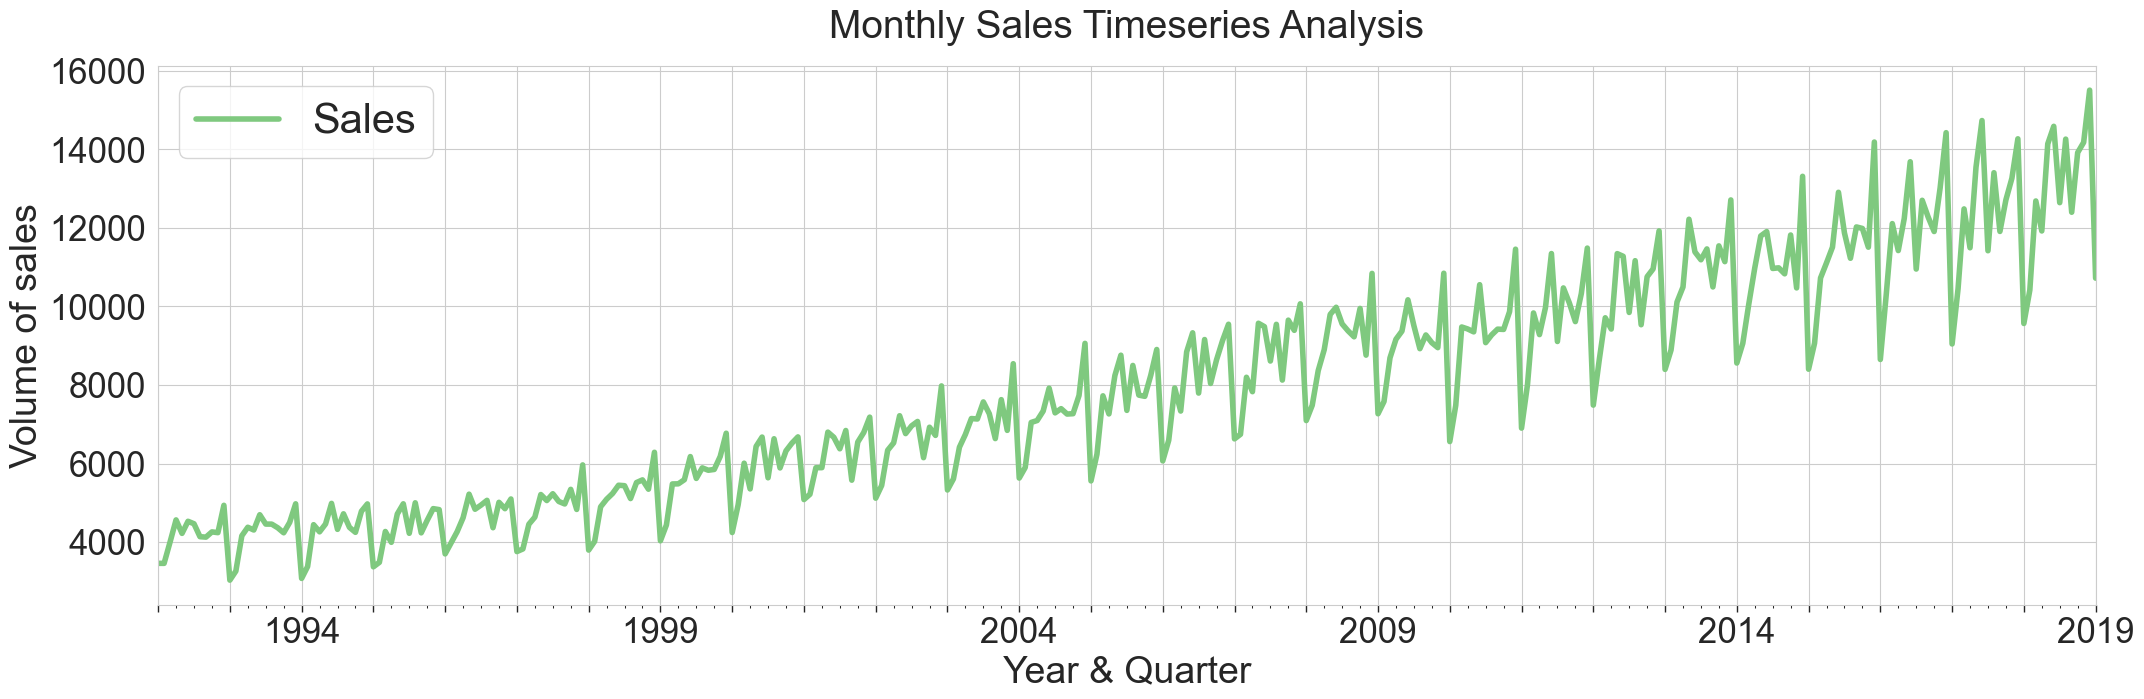

In [40]:
# Plot Timeseries:
ax =  df['Sales'].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)
setup_ticks(ax)
plt.ylabel('Volume of sales', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Monthly Sales Timeseries Analysis', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 30)
plt.xticks(rotation=0,horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

### Step 5: Analyze timeseries: moving averages, trends and volatility.

In [19]:
# Simple Moving Average Trend Analysis
#   --> help to identify areas of support ad resistance.
#   --> filters out random noise / smoothes out fluctuations.

# Windowing (group) every 3 months (1 quarter) to smooth series and find volatility.
df["3M-mAvg"] = df["Sales"].rolling(window=3).mean()
df['3M-vol'] = df['Sales'].rolling(window=3).std()

# Also try exponential weighted moving average:
df['3M-hLife-wExpAvg'] = df["Sales"].ewm(halflife="90 days", times=df.index).mean()
df['3M-hLife-wExpAvg-vol'] = df["Sales"].ewm(halflife="90 days", times=df.index).std()

# And cumulative (all previous points w/o weighting) moving average
df['Cumulative-mAvg'] = df['Sales'].expanding().mean()

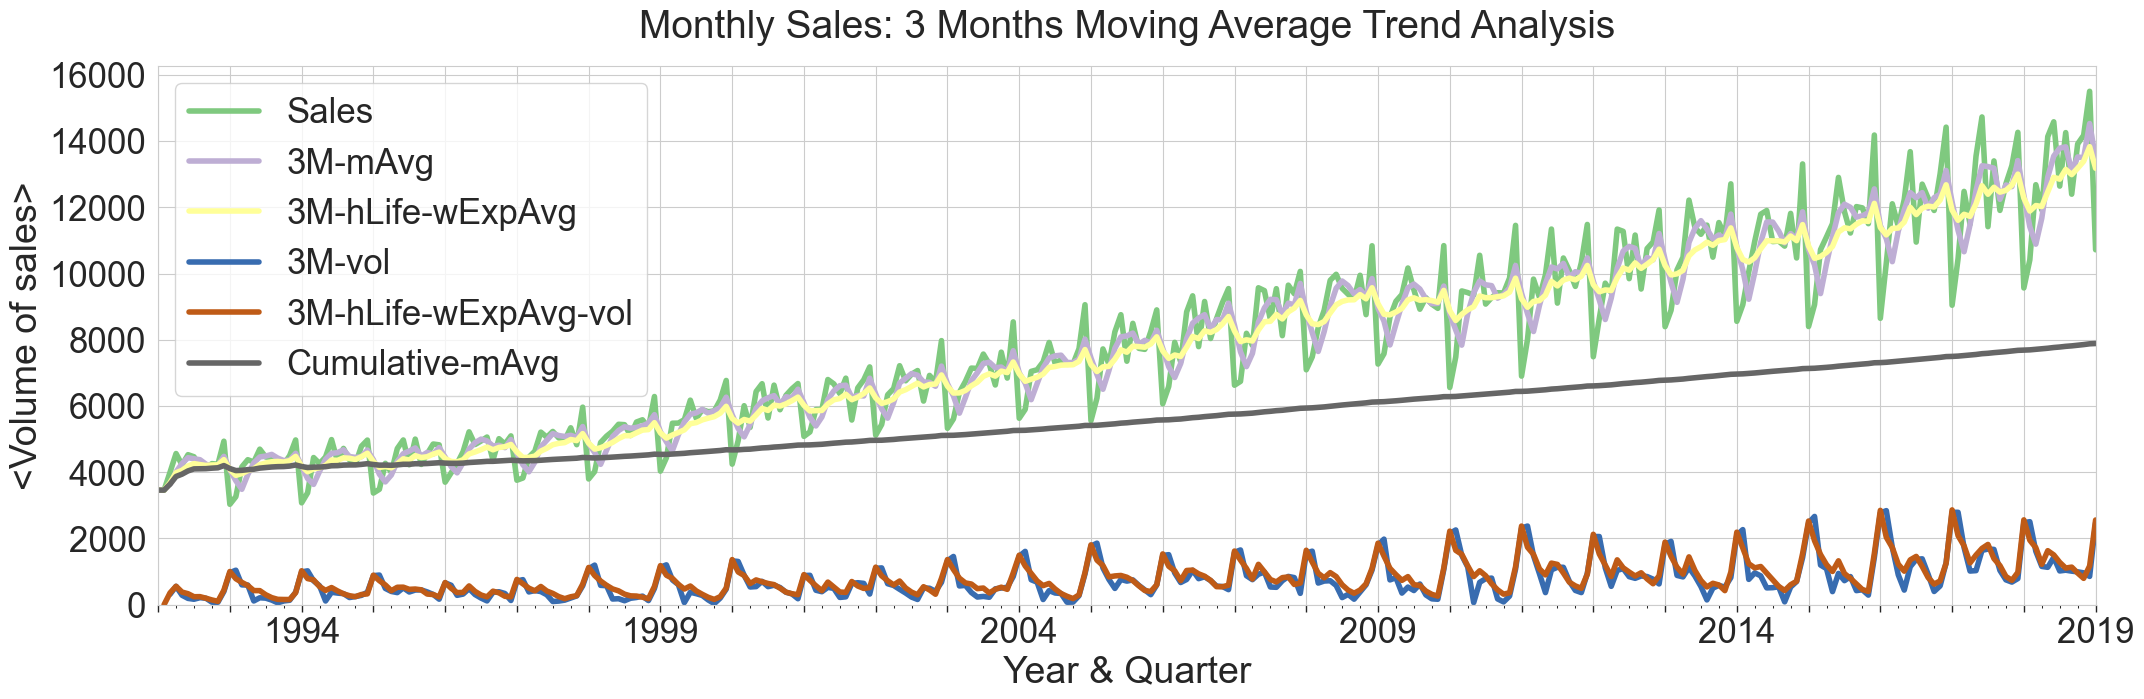

In [36]:
# Plot moving averages and volatility:
ax =  df[['Sales', '3M-mAvg','3M-hLife-wExpAvg','3M-vol','3M-hLife-wExpAvg-vol','Cumulative-mAvg']].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)
setup_ticks(ax)
ax.set_ylim(ymin=0)
plt.ylabel('<Volume of sales>', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Monthly Sales: 3 Months Moving Average Trend Analysis', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 25)
plt.xticks(rotation=0,horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

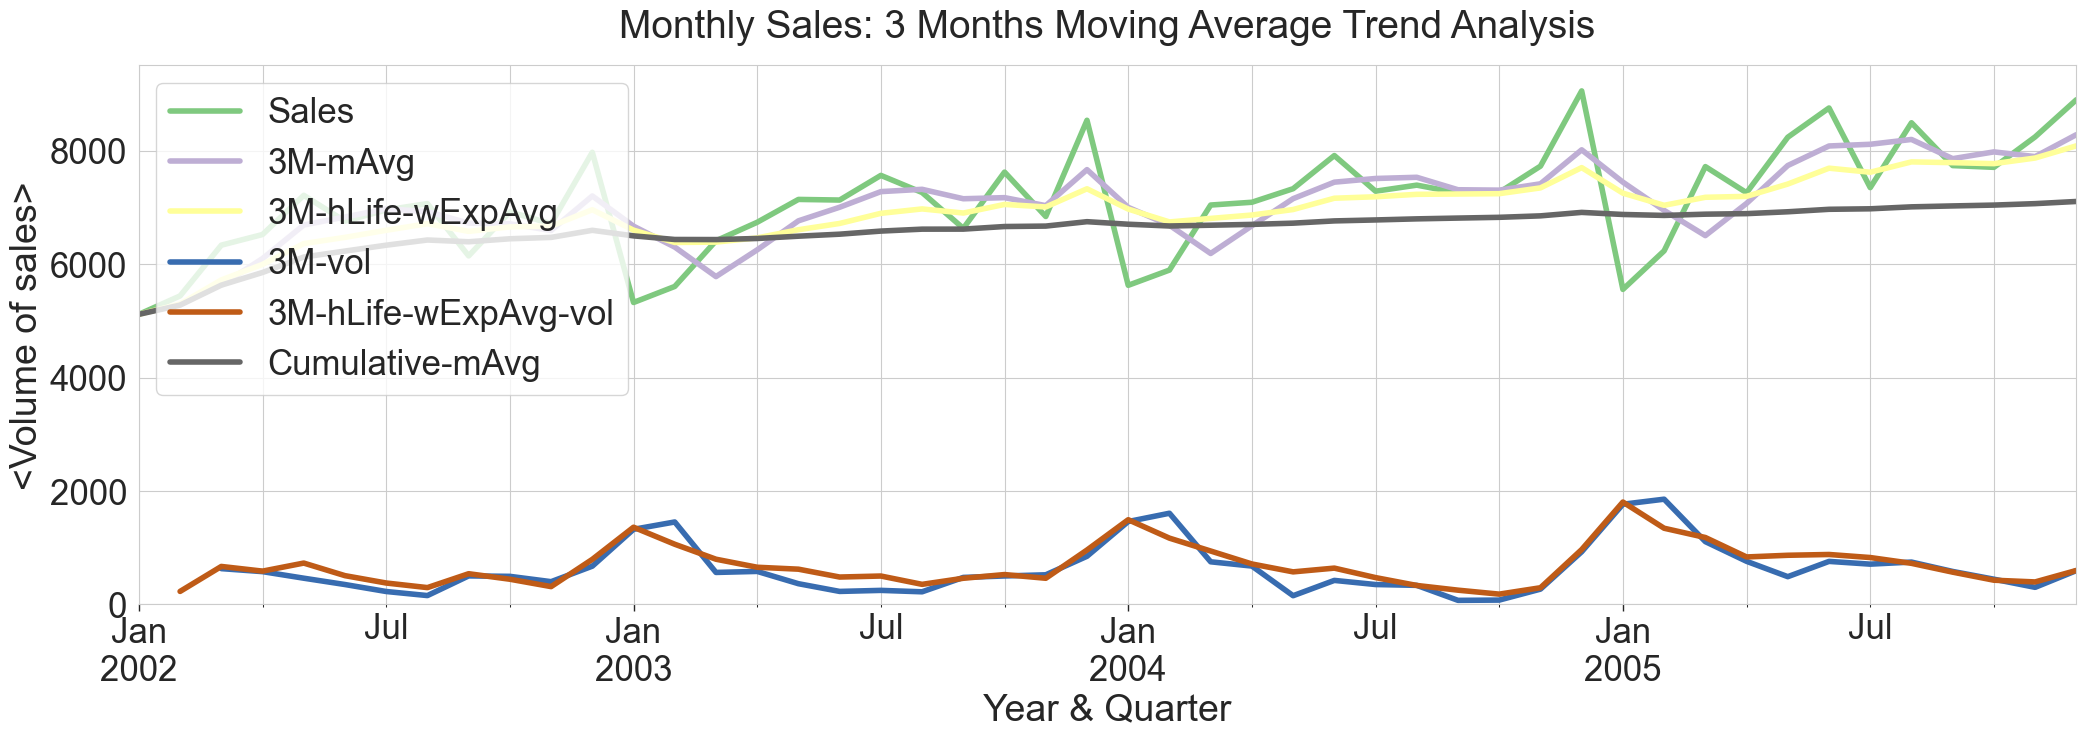

In [42]:
# Let's repeat the plot in a smaller interval.
selector = (df.index.year>=2002) & (df.index.year<2006)
df_small = df[selector].copy()

df_small["3M-mAvg"] = df_small["Sales"].rolling(window=3).mean()
df_small['3M-vol'] = df_small['Sales'].rolling(window=3).std()
df_small['3M-hLife-wExpAvg'] = df_small["Sales"].ewm(halflife="90 days", times=df_small.index).mean()
df_small['3M-hLife-wExpAvg-vol'] = df_small["Sales"].ewm(halflife="90 days", times=df_small.index).std()
df_small['Cumulative-mAvg'] = df_small['Sales'].expanding().mean()

ax = df_small[['Sales', '3M-mAvg','3M-hLife-wExpAvg','3M-vol','3M-hLife-wExpAvg-vol','Cumulative-mAvg']].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)
setup_ticks(ax)
ax.set_ylim(ymin=0)
plt.ylabel('<Volume of sales>', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Monthly Sales: 3 Months Moving Average Trend Analysis', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 25)
plt.xticks(rotation=0,horizontalalignment="center")
ax.xaxis.grid(True, which='minor')
ax.autoscale(enable=True, axis='x', tight=True)

### Summary 2:

* From the rolling 3-months moving averages trendlines:
    - Sales trends up from the beginning to mid of every quarter.
    - Band of resistance occurs at the mid of every quarter.
    - Band of support occurs at the end of every quarter.

* From the volatility:
    - Slightly increases with time, hinting non-stationarity.

* From Cumulative average:
    - Averages lows and highs across history.
    - Slightly increases with time, so company grows slowly but constant.

### Step 6: Timeseries decomposition: trend, cyclical, seasonal, and noise components.

#### Hodrick–Prescott filter ####

* Introduction: also known as Hodrick–Prescott decomposition, it is used in macroeconomics, especially in real business cycle theory, to remove the cyclical (not necessarily seasonal) component of a time series from raw data.
    - Obtains a smoothed-curve (trend) that is more sensitive to long-term than to short-term fluctuations.
        + The adjustment of the sensitivity of the trend to short-term fluctuations is achieved by modifying a multiplier **lambda**.
    - It is a special case of a smoothing spline.

* Theory: Consider x_t is the original series and
  y_t = ln(x_t) = tau_t (trend comp.) + c_t (cyclical comp.) + eps_t (error comp.)
    - To isolate the trend component, find tau_t that minimizes sum_t(y_t - tau_t) ==> penalizes cyclical component.
    - To isolate cyclical component, tau_t is also required to minimize lambda * [(tau_t+1 + tau_t) + (tau_t - tau_t-1) ]^2 ==> lambda gauges the penalization on the increase of the trend component.
    - **lambda ~ 1600 for quarterly data.**
    - In practice, lambda ~ 100 for yearly data, and ~ 14,400 for monthly data.

#### ETS decompsition ####

* Introduction: A more serious analysis would separate a time-series in:
   - Three systematic components (can be modeled): level, trend, seasonality.
   - One non-systematic component: noise/error/residual.

* Definitions:
    - Level: The average value of the complete timeseries.
    - Trend: The increasing or decreasing value in the series --> hpfilter --> in this context, the trend could include "a cyclical", but not seasonal (repetitive) component.
    - Seasonality: The repeating short-term cycle in the series --> the repetitive component --> found by ETS decomposition.
    - Noise: The random variation in the series. --> found by ETS decomposition.

* Theory: Results are obtained by first estimating the trend by applying a convolution filter to the data. The trend is then removed from the series and the average of this de-trended series for each period is the returned seasonal component.

* Implementation: ETS (Error-Trend-Seasonality) decompsition by: https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html
    - Naive decomposition. More sophisticated methods should be preferred.
    - Additive model: Y[t] = T[t] + S[t] + e[t] ==> Use when seasonality and trend components are constant over time.
    - Multiplicative model: Y[t] = T[t] * S[t] * e[t] ==> Use when timeseries looks non-linear.

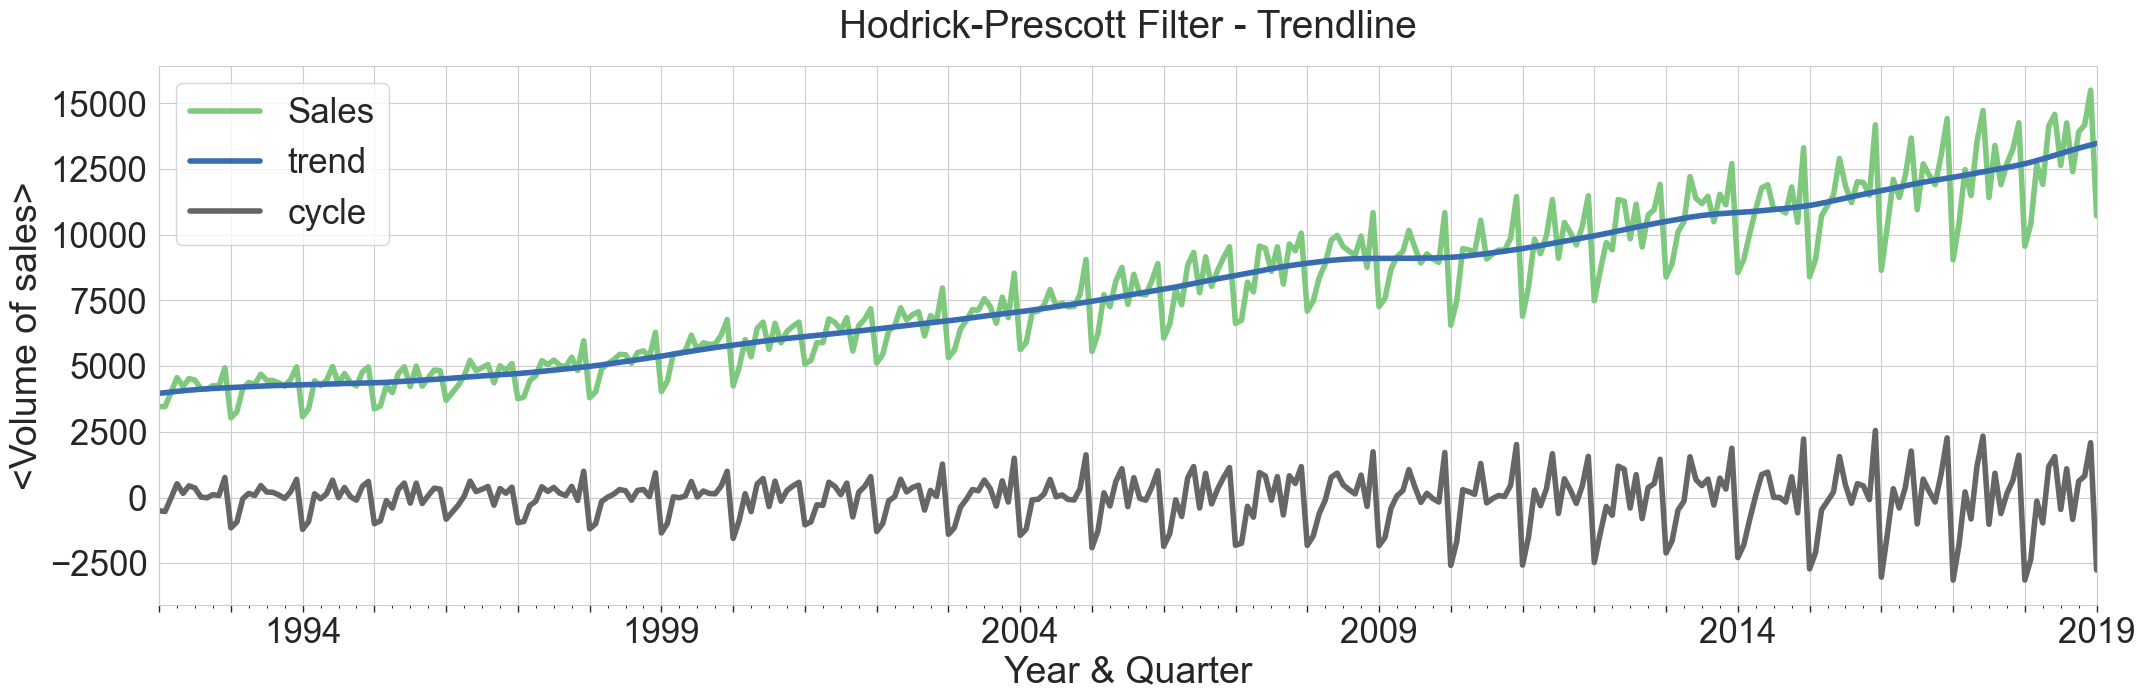

In [45]:
# Hodrick-Prescott Filter:

# Extract cyclical and trend components:
df["cycle"] , df["trend"] = st.tsa.filters.hp_filter.hpfilter(df["Sales"], lamb = 1600)

# Plot timeseries and components:
ax =  df[["Sales","trend","cycle"]].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)
setup_ticks(ax)
plt.ylabel('<Volume of sales>', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Hodrick-Prescott Filter - Trendline', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 25)
plt.xticks(rotation=0,horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

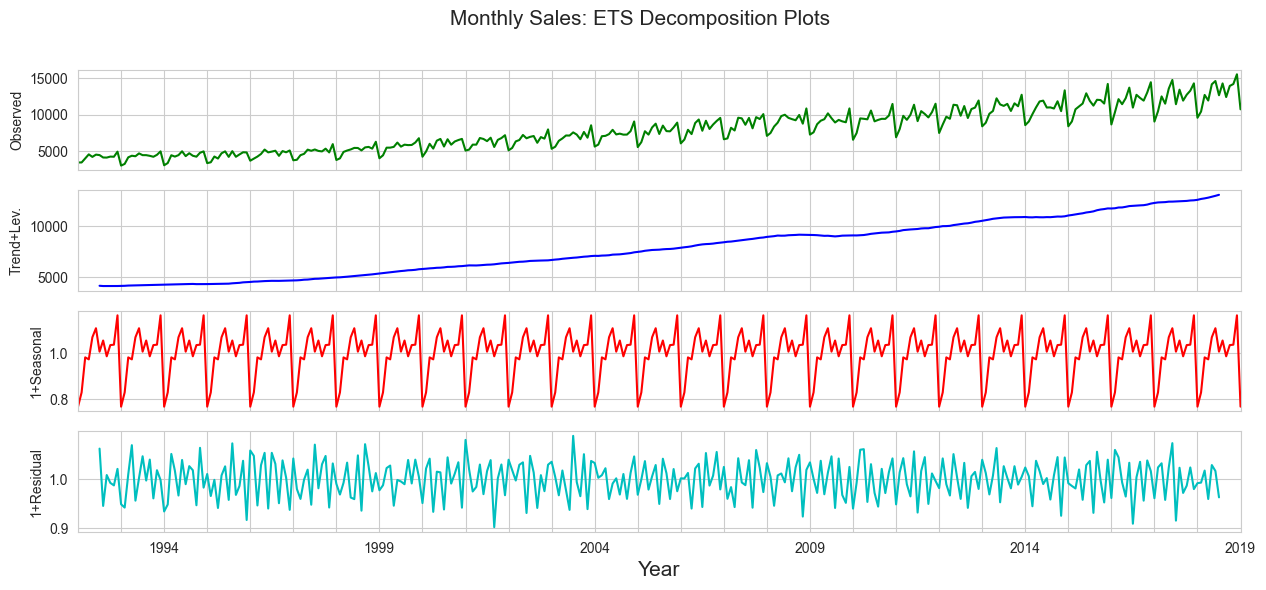

In [63]:
# ETS decomposition: isolate systematic & non-systematic components.

# Since sales increase seems to be non-linear, we use a 'multiplicative' model.
result = st.tsa.seasonal.seasonal_decompose(df["Sales"], model = "multiplicative")

# Plot ETS decomposition:
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(15,6))
fig.suptitle("Monthly Sales: ETS Decomposition Plots", fontsize = "15")
result.observed.plot(ax=axes[0], legend=False, color= 'g')
axes[0].set_ylabel('Observed')
result.trend.plot(ax=axes[1], legend=False, color = 'b')
axes[1].set_ylabel('Trend+Lev.')
result.seasonal.plot(ax=axes[2], legend=False, color = 'r')
axes[2].set_ylabel('1+Seasonal')
result.resid.plot(ax=axes[3], legend=False, color = 'c')
axes[3].set_ylabel('1+Residual')
plt.xlabel('Year', fontsize = 15)
for i in [0,1,2,3] : axes[i].xaxis.set_major_locator(plticker.MultipleLocator(base=12))
ax.autoscale(enable=True, axis='x', tight=False)

#### Summary 3:

* The trendline confirms an overall growth pattern at a non-linear rate over the course of time.
* The seasonal component shows clearly the annual (12 months) period.

### Step 7: Timeseries lag analysis: auto-correlations.

* Motivation: Check seasonality by taking "lags", which are linear regressions between x_t and x_t-k, where k = 1,2,3,... If timeseries is periodic, the corresponding "auto-correlations" (ACs) should be periodic too.

* **IMPORTANT**: As we will see later, for an "Autoregressive" model (AR), one examines the "PACF" plots to find the lag after which the Partial-ACs are all within the confidence interval. This lag is determined to likely be the AR model's order.

#### Auto-correlation Functions (ACF) ####

* ACF plots the linear correlation coefficients between points x_t in the timeseries and past points x_t-k vs. k=1,2,3,...
    - Summarize all the information of lag plots: linear regression between x_t and x_t-k.

#### Partial Auto-correlation Functions (PACF) ###

* Definition: A partial autocorrelation is the amount of correlation between a variable and a lag of itself that is not explained by correlations at all lower-order-lags.
    - https://en.wikipedia.org/wiki/Partial_autocorrelation_function
    - Partial auto-correlation between x_t and x_t-k removes the contribution to the correlation due to other lags x_t-l, for l = 1,2,..,k-1.
    - E.g., ACs might be significant for a large number of lags -- but perhaps the ACs at lags 2 and above are merely due to the propagation of the AC at lag 1. This can be confirmed by the PACF plot.

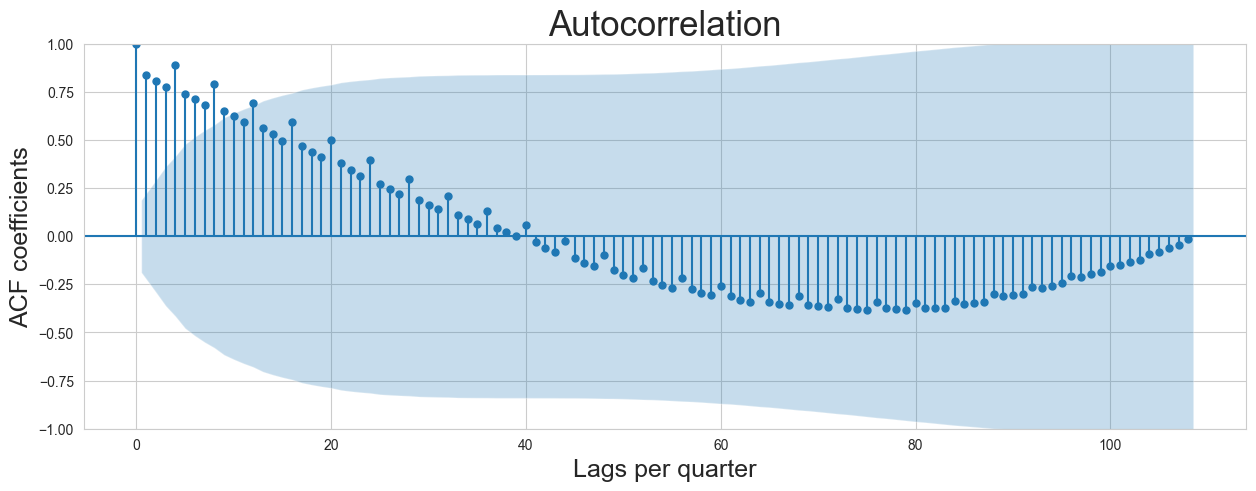

In [65]:
# Plot ACF:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
st.graphics.tsaplots.plot_acf(df.asfreq(freq ='3MS')["Sales"],lags=108, alpha=0.05,ax=ax) #(df.shape[0]-1)
plt.ylabel('ACF coefficients', fontsize = 18)
plt.xlabel('Lags per quarter', fontsize = 18)
plt.title('Autocorrelation', fontsize = 25)
ax.autoscale(enable=True, axis='x', tight=False)

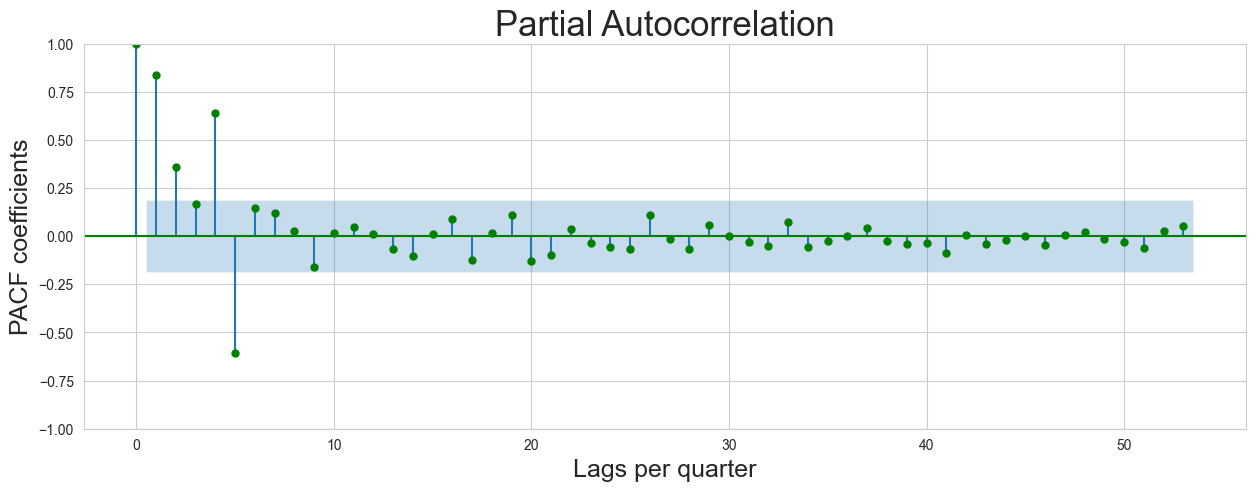

In [66]:
# Plot PACF:
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(111)
st.graphics.tsaplots.plot_pacf(df.asfreq(freq ='3MS')["Sales"].dropna(), lags = np.arange(108/2), c='g', ax = ax);
plt.ylabel('PACF coefficients', fontsize = 18)
plt.xlabel('Lags per quarter', fontsize = 18)
plt.title('Partial Autocorrelation', fontsize = 25)
ax.autoscale(enable=True, axis='x', tight=False)

#### Summary 4:

* From ACF plot:
    - Linear correlation peaks every year (seasonality) .
    - Linear correlations are significant for ~ 2-3 years.
    - Linear correlations change sign every ~40*4/12 ~ 13 years.

* From PACF plot:
    - PACs are **significant for less than 6 months**.
    - Certainly it **peaks in year-1 and probably in year-2**.

* As we will see later, an AR model of this timeseries should be of order p ~ 3-6 months (non-seasonal component) and P = 1-2 years (seasonal component).

### Step 8: Timeseries Differentiation: find a simple -- stationary -- timeseries.

* Motivation: dv/dt = a (constant) is equivalent to v(t) = at + a_0. The first is a simpler description of the phenomena involved. By calculating differences of 'v' (derivatives) in the data, we can easily determine the constant 'a'. Finally, look at the data for a_0 = v(t=0). The problem is solved. No need to do any linear regression to v(t).

  The same logic applies to timeseries and forecasting.

*Bottonline*:
**Take differences to simplify the math.**

#### Stationary timeseries ####

More in: https://otexts.com/fpp2/stationarity.html

* Definition: **A stationary time series is one whose properties do not depend on the time** (e.g. volatility) at which the series is observed. Thus, time series with trends, or with seasonality, are not stationary — the trend and seasonality will affect the value of the time series at different times.
    - A white noise series is stationary — it does not matter when you observe it, it should look much the same at any point in time.
    - A time series with cyclic behaviour (but with no trend or seasonality) is stationary. This is because the cycles are not of a fixed length, so before we observe the series we cannot be sure where the peaks and troughs of the cycles will be.

#### (Non-)Stationary Tests ####

* NON-stationarity (or unit root) tests:
    1. ADF (Augmented Dickey-Fuller) test for stationarity:
       - H0 = non-stationary timeseries; H1 = stationarity (p<0.05).
    2. KPSS (Kwiatkowski-Phillips-Schmidt-Shin):
       - H0 = stationary; H1 = non-stationary.

#### Timeseries DIFFERENTIATION ####

* Definition: if x_t is the original timeseries, FIRST DIFFERENTATION is defined as
  x_t' = x_t - x_t-1 = x_t - L(x_t) = (1-L)x_t, where L is the lag operator.
    - If x_t' = eps = white noise, x_t' is a random walk (unpredictable).
    - "Nth-order differentiation" (e.g. x_t'' = x_t' - x_t-1') is shown to be x_t^(N) = (1-L)^N x_t.
    - Simple (N=1) and seasonal (e.g. N=12) differentiation can be both applied one after the other to make the timeseries stationary.
    - E.g., x_t' is equivalent to daily returns of stocks.


In [67]:
# Define functions that returns ADF and KPPS test results:

def adf_test(series,title=''):
    print(f'Augmented Dickey-Fuller Test: {title}')
    result = st.tsa.stattools.adfuller(series.dropna(),autolag='AIC') #.dropna() handles differenced data
    # fill first 4 indices
    labels = ['ADF test statistic','p-value','# lags used','# observations']
    out = pd.Series(result[0:4],index=labels)
    # fill 5th index by hand (critical values)
    for key,val in result[4].items():
        out[f'critical value ({key})']=val
    print(out.to_string())  # .to_string() removes the line "dtype: float64"
    if result[1] <= 0.05:
        print("Strong evidence against the null hypothesis")
        print("Reject the null hypothesis")
        print("Data has no unit root and is stationary")
    else:
        print("Weak evidence against the null hypothesis")
        print("Fail to reject the null hypothesis")
        print("Data has a unit root and is non-stationary")

def kpss_test(timeseries):
    print ('Results of KPSS Test:')
    kpsstest = st.tsa.stattools.kpss(timeseries, regression='c')
    kpss_output = pd.Series(kpsstest[0:3], index=
    ['Test Statistic','p-value','Lags Used'])
    for key,value in kpsstest[3].items():
        kpss_output['Critical Value (%s)'%key] = value
        print (kpss_output)

In [68]:
# Do ADF test to Sale timeseries:
adf_test(df["Sales"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic        2.037405
p-value                   0.998720
# lags used              14.000000
# observations          310.000000
critical value (1%)      -3.451622
critical value (5%)      -2.870909
critical value (10%)     -2.571762
Weak evidence against the null hypothesis
Fail to reject the null hypothesis
Data has a unit root and is non-stationary


In [69]:
# Do KPSS test to Sale timeseries:
kpss_test(df["Sales"])

Results of KPSS Test:
Test Statistic           2.79443
p-value                  0.01000
Lags Used               11.00000
Critical Value (10%)     0.34700
dtype: float64
Test Statistic           2.79443
p-value                  0.01000
Lags Used               11.00000
Critical Value (10%)     0.34700
Critical Value (5%)      0.46300
dtype: float64
Test Statistic            2.79443
p-value                   0.01000
Lags Used                11.00000
Critical Value (10%)      0.34700
Critical Value (5%)       0.46300
Critical Value (2.5%)     0.57400
dtype: float64
Test Statistic            2.79443
p-value                   0.01000
Lags Used                11.00000
Critical Value (10%)      0.34700
Critical Value (5%)       0.46300
Critical Value (2.5%)     0.57400
Critical Value (1%)       0.73900
dtype: float64


/var/folders/px/hp6xtxyn7vl1zq8_k8x1f5kw0000gn/T/ipykernel_56465/2931674564.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpsstest = st.tsa.stattools.kpss(timeseries, regression='c')


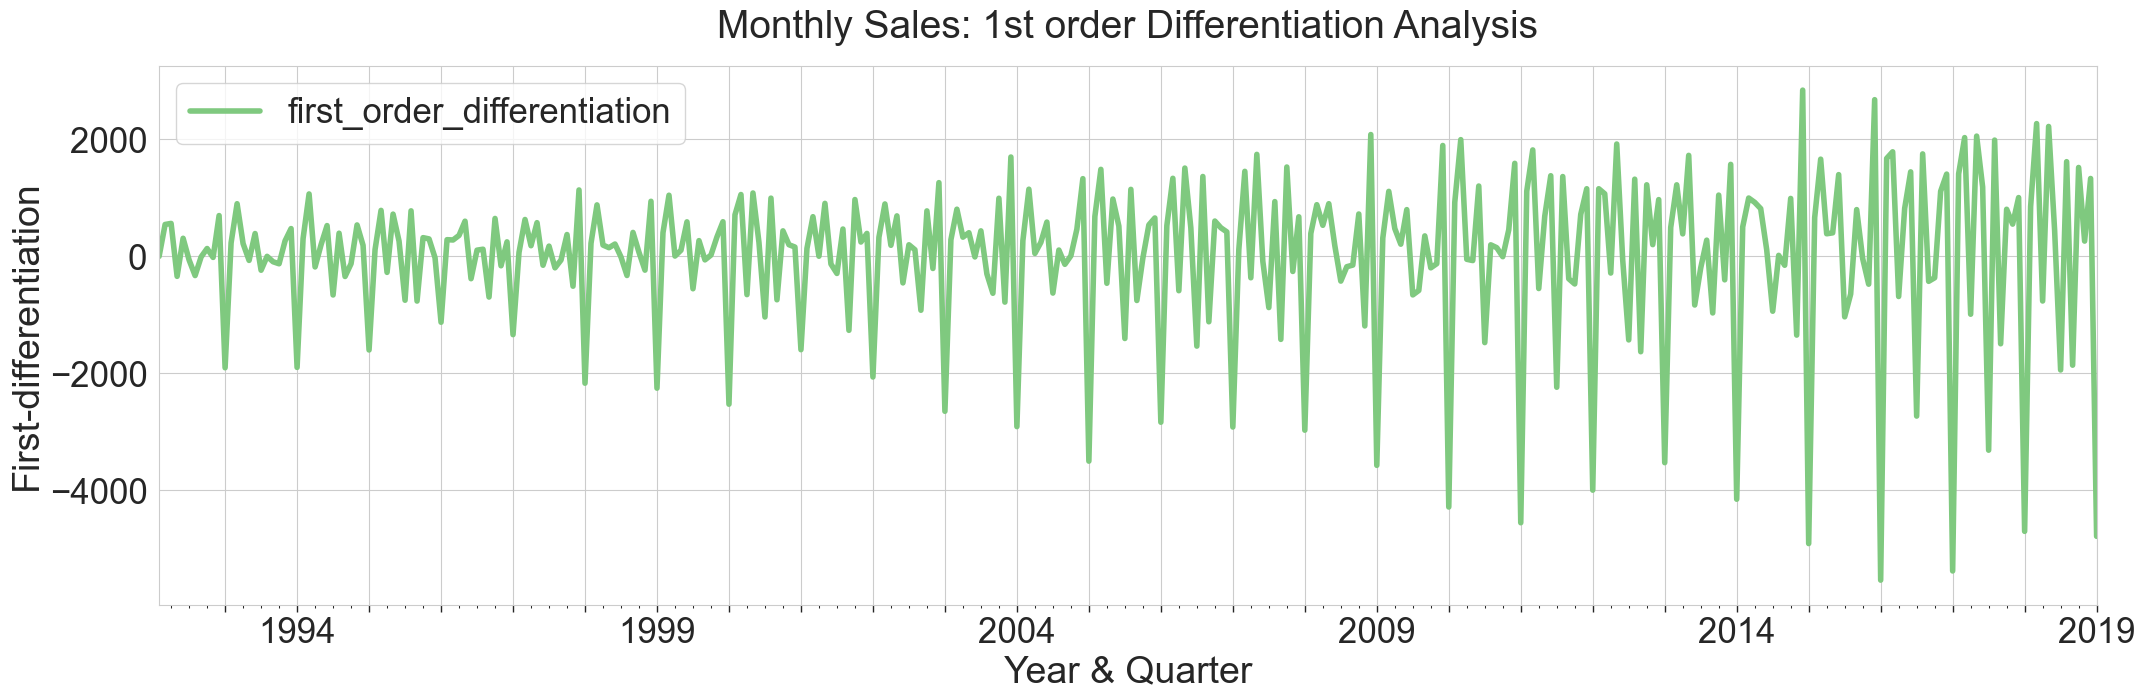

In [70]:
df["first_order_differentiation"] = st.tsa.statespace.tools.diff(df["Sales"], k_diff = 1)

ax =  df["first_order_differentiation"].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)
setup_ticks(ax)
plt.ylabel('First-differentiation', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Monthly Sales: 1st order Differentiation Analysis', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 25)
plt.xticks(rotation=0,horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

In [71]:
# ADF test for stationarity of first simple differentation. PASS!!
adf_test(df["first_order_differentiation"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic       -4.365960
p-value                   0.000341
# lags used              13.000000
# observations          310.000000
critical value (1%)      -3.451622
critical value (5%)      -2.870909
critical value (10%)     -2.571762
Strong evidence against the null hypothesis
Reject the null hypothesis
Data has no unit root and is stationary


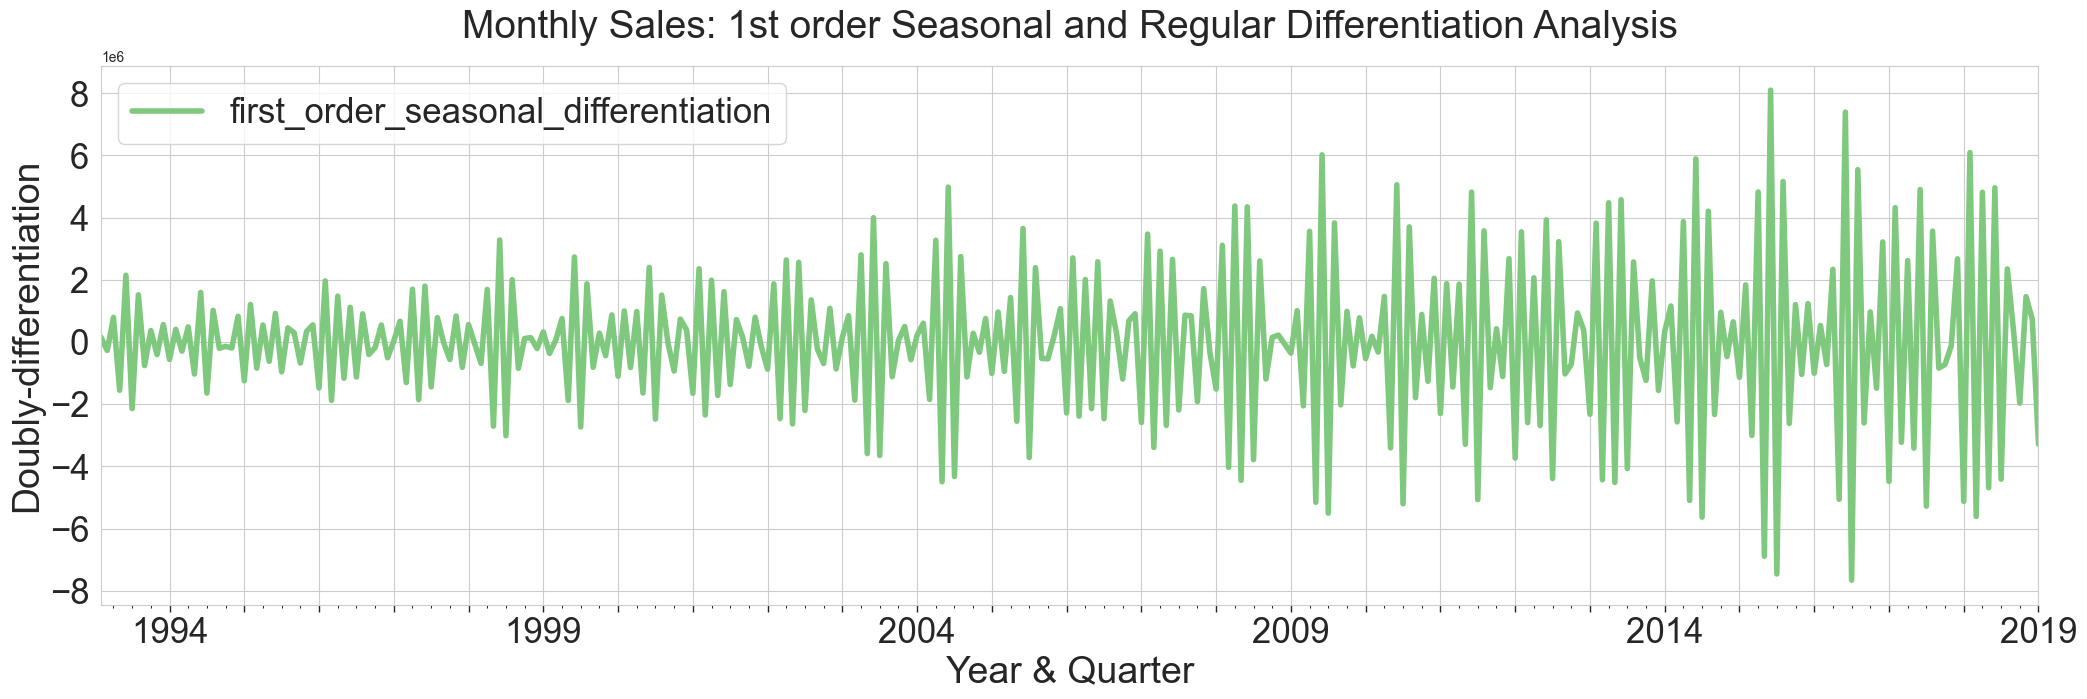

In [72]:
# What about subtracting 12-month periodicity? Peaks appear much more randomly.
df["first_order_seasonal_differentiation"] = st.tsa.statespace.tools.diff(df["first_order_differentiation"], k_diff = 12)

ax =  df["first_order_seasonal_differentiation"].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)
setup_ticks(ax)
plt.ylabel('Doubly-differentiation', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Monthly Sales: 1st order Seasonal and Regular Differentiation Analysis', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 25)
plt.xticks(rotation=0,horizontalalignment="center")
ax.autoscale(enable=True, axis='x', tight=True)

In [73]:
# Last check for stationarity to doubly-differentiated timeseries. PASS TOO!
adf_test(df["first_order_seasonal_differentiation"], title = "Automated ADF Test for Stationarity")

Augmented Dickey-Fuller Test: Automated ADF Test for Stationarity
ADF test statistic      -23.401364
p-value                   0.000000
# lags used              16.000000
# observations          295.000000
critical value (1%)      -3.452713
critical value (5%)      -2.871388
critical value (10%)     -2.572017
Strong evidence against the null hypothesis
Reject the null hypothesis
Data has no unit root and is stationary


#### Summary 5:

* Original sales series is not stationary, as found by ADF and KPSS tests.
* First differentiation makes the timeseries stationary.
* Additional seasonal differentiation make it even more stationary.

**We are almost ready to forecast!**

### Step 9: Timeseries Modeling

#### ARIMA models ####

* Theory:
    1. An autoregressive model of order p, AM(p), for a timeseries follows:
    x_t = c + f_1 x_t-1 + f_2 x_t-2 + ... + f_p x_t-p + eps_t
   where eps_t is white noise.
    2. A moving average model of order q, MA(q), for a timeseries follows:
    x_t = c + eps_t + g_1 eps_t-1 + g_2 eps_t-2 + ... + g_q eps_t-q
   where eps_t is white noise and eps_t-k are forecast errors in a regression-like model.
    3. **A "non-seasonal" ARIMA(p,d,q) model for a x_t timeseries** follows:
    y_t = c + f_1 y_t-1 + ... + f_p y_t-p + g_1 eps_t-1 + ... + g_q eps_t-q + eps_t
   where y_t = x_t^(d) = (1-L)^d x_t is the "d"-differentiated series.
        - Equivalent to:
        (1 - f_1 L - ... - f_p B^p)(1-L)^d x_t = c + (1 + g_1 L + ... + g_q L^q)eps_t
        or simply: **AR(p)(1-L)^d x_t = MA(q)**

* Notes:
    1. **Coefficients are estimated by maximum (log) likelihood estimation (MLE).**
    2. **Useful to determine the order of p and q is to minimize the Akaike’s Info. Criterion (AIC)**: AIC = -2 log(L) + 2(p + q + s + 1), where s = 1 if c!=0 (s=0 if c=0).
    3. Corrected AIC (AICc) is defined in https://otexts.com/fpp2/arima-estimation.html
    4. **A good model should return stationary residuals (errors) or return Ljung-Box Q-test H0 true.**

* Examples:
    1. ARIMA(0,0,0) --> x_t = c + eps_t --> white noise.
    2. ARIMA(0,1,0) w/ c=0 --> x_t' = eps_t --> x_t = x_t-1 + eps_t --> random walk.
    3. ARIMA(0,1,0) w/ c!=0 --> random walk with drift.
    4. ARIMA(p,0,0) = AR(p) or ARIMA(0,0,q) = AM(q).

* Observations:
    1. If c=0 and d=0, the long-term forecasts will go to zero.
    2. If c=0 and d=1, the long-term forecasts will go to a non-zero constant.
    3. If c=0 and d=2, the long-term forecasts will follow a straight line.
    4. **If c!=0 and d=0, the long-term forecasts will go to the mean of the data.**
    5. If c!=0 and d=1, the long-term forecasts will follow a straight line.
    6. If c!=0 and d=2, the long-term forecasts will follow a quadratic trend.

* Results:
    1. The higher the value of d, the more rapidly the prediction intervals increase in size. If d=0, the forecast stdev. will go to the historical stdev.
    2. **Data follows ARIMA(p,d,0) if:**
       - **the ACF is exponentially decaying or sinusoidal;**
       - **there is a significant spike at lag p in PACF, but none beyond lag p.**
    3. If data follows ARIMA(0,d,q):
       - the PACF is exponentially decaying or sinusoidal;
       - there is a significant spike at lag q in the ACF, but none beyond lag q.

* **Generalization for seasonal (S) time-series (SARIMA model)**:
    1. Identify **seasonality period m = number of observations per year**.
    2. Extend the **ARIMA(p,d,q)(P,D,Q)[m] model** for some (P,D,Q), besides (p,d,q):
       **AR(Q)AR(p)(1-L)^D(1-L)^d x_t = MA(Q)MA(q)**

* **In summary: From our previous Diffentiation and ACF and PACF analysis, m=12, d=1, D=1, p ~ 3-6 months ( 1 or 2 quarters), P ~ 1 and at most 2 years (12 or 24 months).**

In [74]:
# Let's use auto_arima to find SARIMA orders:
print(pmdarima.auto_arima(df["Sales"], seasonal = True, m=12, error_action = "ignore").summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  325
Model:             SARIMAX(3, 1, 2)x(2, 1, 2, 12)   Log Likelihood               -2212.240
Date:                            Wed, 11 Oct 2023   AIC                           4444.480
Time:                                    22:59:51   BIC                           4481.910
Sample:                                01-01-1992   HQIC                          4459.440
                                     - 01-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0776      0.221     -0.350      0.726      -0.512       0.356
ar.L2          0.0948      0.089   

In [75]:
"""
Revalidate SARIMA orders using 'stepwise' option (Hyndman and Khandakar algorithm, https://otexts.com/fpp2/arima-r.html), instead of trying sequentially or randomly. Fit calls scipy.optimize (default lbfgs).

Doc: https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html
Options:
- out_of_sample_size=365 (if you want to use the last 365 days as test sample). Forecasting will in any case start after this set. Use 'mse' for 'scoring'.
- d=None, D=none: use kpss to determine diff. orders.
"""

stepwise_fit = pmdarima.auto_arima(df["Sales"], m=12, d=1, D=1, start_p=3, max_p=6, start_P=1, max_P=3, max_q=5, max_Q=5, seasonal=True, trace=True, suppress_warnings=True, stepwise=True) # error_action='ignore',

Performing stepwise search to minimize aic
 ARIMA(3,1,2)(1,1,1)[12]             : AIC=4506.197, Time=7.13 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=4868.181, Time=0.08 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=4731.674, Time=0.76 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=4629.449, Time=2.26 sec
 ARIMA(3,1,2)(0,1,1)[12]             : AIC=4520.022, Time=37.06 sec
 ARIMA(3,1,2)(1,1,0)[12]             : AIC=4528.781, Time=4.15 sec
 ARIMA(3,1,2)(2,1,1)[12]             : AIC=4491.408, Time=15.17 sec
 ARIMA(3,1,2)(2,1,0)[12]             : AIC=4514.299, Time=6.98 sec
 ARIMA(3,1,2)(3,1,1)[12]             : AIC=4473.673, Time=18.97 sec
 ARIMA(3,1,2)(3,1,0)[12]             : AIC=4493.748, Time=12.08 sec
 ARIMA(3,1,2)(3,1,2)[12]             : AIC=4450.776, Time=22.36 sec
 ARIMA(3,1,2)(2,1,2)[12]             : AIC=4444.480, Time=9.72 sec
 ARIMA(3,1,2)(1,1,2)[12]             : AIC=4499.385, Time=4.79 sec
 ARIMA(3,1,2)(2,1,3)[12]             : AIC=4449.941, Time=21.17 sec
 ARIMA(3,1,2)

#### Summary 6:

* Using naive (random choices) auto_arima:
    - Best result: SARIMAX(3, 1, 2)x(2, 1, 2)[12]
    - The Ljung-Box test (p_val = 0.68) shows that the residuals (errors) have no remaining autocorrelations.
* Using stepwise option (Hyndman and Khandakar algorithm) in auto_arima:
    - Best model minimizes AIC and must be 'invertible'.
    - Confirms naive search.

### Step 10: Fit Sarima Model with training sample.

* Divide train/test datasets.
* Fit model in training sample.
* Testing data are the last points in timeseries. Here 23 out 325 points, or 2 years.

In [76]:
# Training set:
train_percentage = 0.93
train_npoints = int(len(df)*train_percentage)
print("Training with ", str(train_npoints), " points.")
df_train = df.iloc[:train_npoints,:1] #just take first column ('Sales')
df_train.tail(2)

Training with  302  points.


,Sales
Month,
2017-01-01,9043
2017-02-01,10452


In [77]:
# Testing set:
df_test = df.iloc[train_npoints:, :1]
print("Testing with the last ", str(df_test.shape[0]), " points.")
df_test.head(2)

Testing with the last  23  points.


,Sales
Month,
2017-03-01,12481
2017-04-01,11491


In [78]:
# Fit SARIMAX model with the orders we found, using training data:
# More in:
# https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_sarimax_stata.html
# https://www.statsmodels.org/dev/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
# https://www.statsmodels.org/dev/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.fit.html

fitted_SARIMA_model = st.tsa.statespace.sarimax.SARIMAX(df_train["Sales"], order =(3,1,2), seasonal_order = (2,1,2,12))

#increasing maxiter to converge.
results = fitted_SARIMA_model.fit(maxiter=150)

/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           10     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.34502D+00    |proj g|=  4.08240D+00

At iterate    5    f=  6.81118D+00    |proj g|=  6.12505D-02

At iterate   10    f=  6.78855D+00    |proj g|=  7.83403D-03

At iterate   15    f=  6.78596D+00    |proj g|=  2.29020D-02

At iterate   20    f=  6.78552D+00    |proj g|=  2.96191D-03

At iterate   25    f=  6.78439D+00    |proj g|=  1.07395D-02

At iterate   30    f=  6.78360D+00    |proj g|=  2.99956D-03

At iterate   35    f=  6.78355D+00    |proj g|=  2.20609D-03

At iterate   40    f=  6.78348D+00    |proj g|=  3.90861D-03

At iterate   45    f=  6.78205D+00    |proj g|=  2.23741D-02

At iterate   50    f=  6.77493D+00    |proj g|=  4.60380D-02

At iterate   55    f=  6.76685D+00    |proj g|=  1.05915D-02

At iterate   60    f=  6.76578D+00    |proj g|=  8.58115D-03

At iterate   65    f=  6.7

In [79]:
print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                  302
Model:             SARIMAX(3, 1, 2)x(2, 1, 2, 12)   Log Likelihood               -2039.091
Date:                            Wed, 11 Oct 2023   AIC                           4098.182
Time:                                    23:13:55   BIC                           4134.846
Sample:                                01-01-1992   HQIC                          4112.873
                                     - 02-01-2017                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1279      0.186     -0.688      0.491      -0.492       0.236
ar.L2          0.1228      0.078   

#### Summary 7:

* The fit converged in the end!
* The Ljung-Box (residuals stationarity) test improved to p_val = 0.81.

### Step 11: Model performance in testing sample.

* Predict results in testing samples.
* Use MSE to calculate a naive confidence region of predictions.

In [80]:
# Predict test points:
test_SARIMA_predictions = results.predict(start=df_train.shape[0], end=(df.shape[0] - 1)).rename('SARIMA-Predicted Sales')

# Print MSE:
mse = np.sqrt(sklearn.metrics.mean_squared_error(df_test, test_SARIMA_predictions))
print("Root Mean Squared Error = ", str(round(mse,2)))

# Include actual values to compare with predictions:
test_SARIMA_predictions = pd.DataFrame(test_SARIMA_predictions).round(decimals=1).join(df_test['Sales'])

# Include +/- MSE band in test_SARIMA_predictions:
test_SARIMA_predictions["Predicted Inbound Variance"] = (test_SARIMA_predictions["SARIMA-Predicted Sales"]-mse).round(decimals=1)
test_SARIMA_predictions["Predicted Outbound Variance"]= (test_SARIMA_predictions["SARIMA-Predicted Sales"]+mse).round(decimals=1)

test_SARIMA_predictions

Root Mean Squared Error =  355.11


,SARIMA-Predicted Sales,Sales,Predicted Inbound Variance,Predicted Outbound Variance
2017-03-01,12332.3,12481,11977.2,12687.4
2017-04-01,11611.7,11491,11256.6,11966.8
2017-05-01,13221.5,13545,12866.4,13576.6
2017-06-01,13846.6,14730,13491.5,14201.7
2017-07-01,11413.1,11416,11058.0,11768.2
2017-08-01,13536.6,13402,13181.5,13891.7
2017-09-01,12356.3,11907,12001.2,12711.4
2017-10-01,12670.3,12711,12315.2,13025.4
2017-11-01,13558.7,13261,13203.6,13913.8
2017-12-01,14605.4,14265,14250.3,14960.5


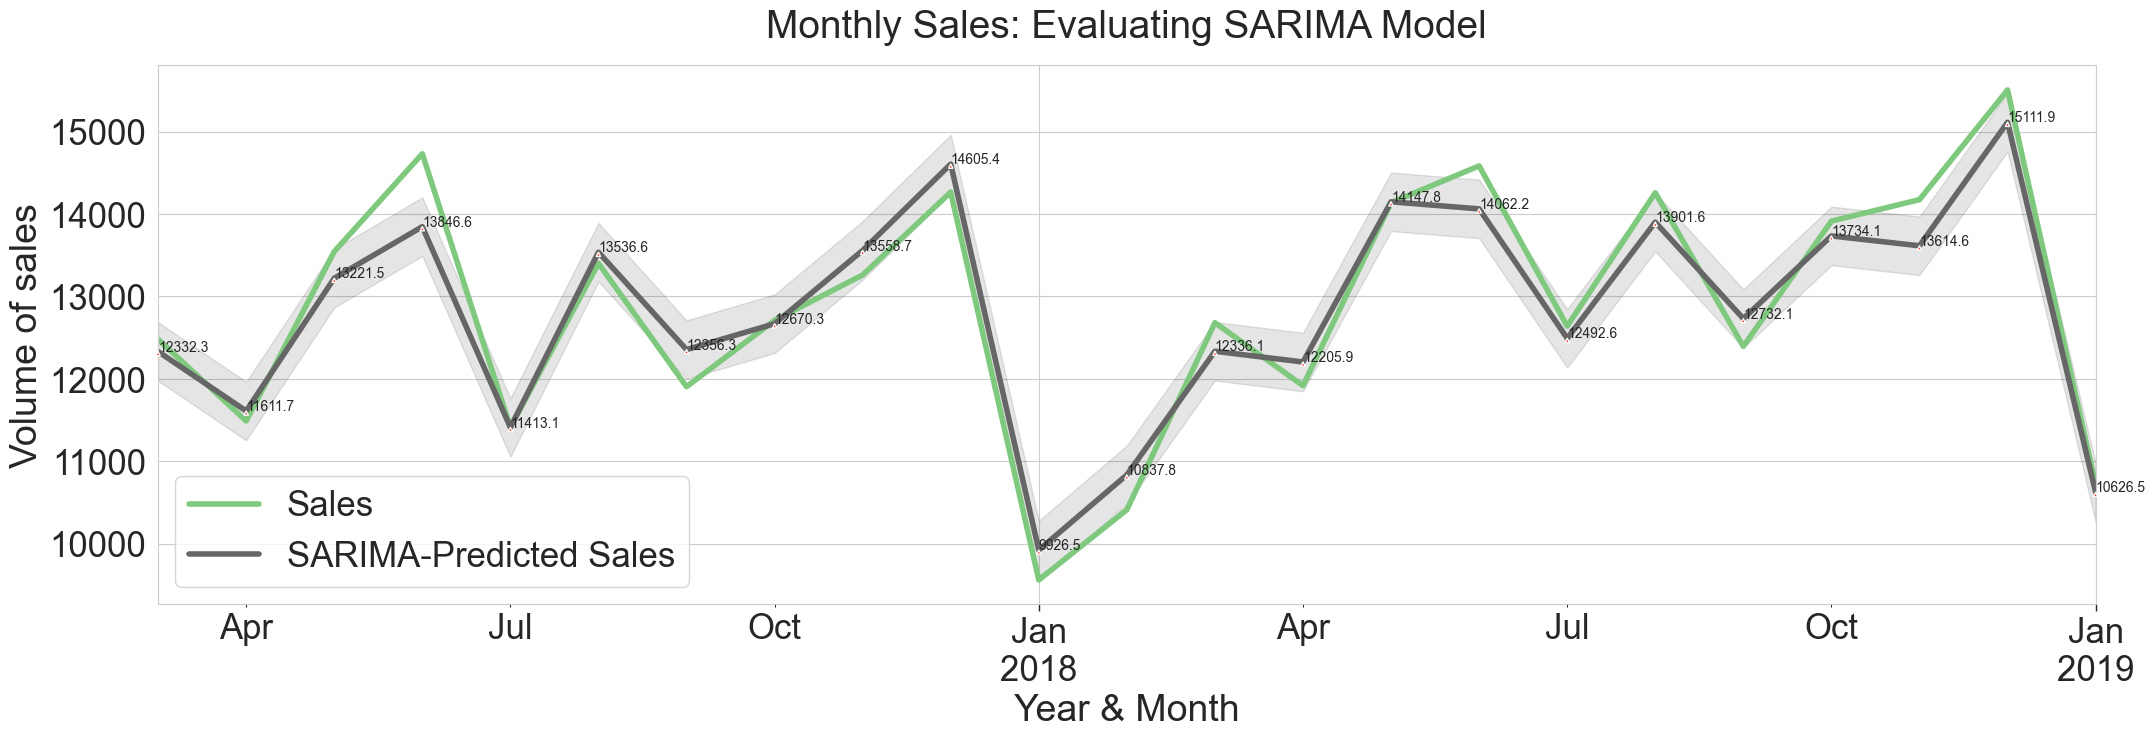

In [84]:
#Plot the Graph:

ax = test_SARIMA_predictions[["Sales", "SARIMA-Predicted Sales"]].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)

ax.fill_between(test_SARIMA_predictions.index, test_SARIMA_predictions['Predicted Inbound Variance'], test_SARIMA_predictions['Predicted Outbound Variance'], color='k', alpha=0.1);

for i in np.arange(0,len(test_SARIMA_predictions)):
    ax.annotate(str(test_SARIMA_predictions["SARIMA-Predicted Sales"][i]),
                xy=(test_SARIMA_predictions.index[i], test_SARIMA_predictions["SARIMA-Predicted Sales"][i]), xycoords='data', xytext=(test_SARIMA_predictions.index[i],test_SARIMA_predictions["SARIMA-Predicted Sales"][i]+5), arrowprops=dict(facecolor='r', headwidth=3, headlength=3 )) #shrink=0.05

#Configure x and y labels:
setup_ticks(ax)
plt.ylabel('Volume of sales', fontsize = 27)
plt.xlabel('Year & Month', fontsize = 27)
plt.title('Monthly Sales: Evaluating SARIMA Model', fontsize = 28, pad=20)
plt.legend(loc='lower left', fontsize = 25)
plt.xticks(rotation=0)
ax.autoscale(enable=True, axis='x', tight=True)

#### Summary 8:

* The chosen ARIMA model does a good job predicting sales in testing sampl.

* Using +/-MSE as confidence band is covering ~2/3 of real points, as expected for a 1 sigma coverage. Still, these confidence intervals are non-precise.
    - In principle, we can use .get_predictions() as explained in https://www.statsmodels.org/dev/examples/notebooks/generated/statespace_forecasting.html#Prediction-vs-Forecasting to obtain reliable error bands.

### Step 12: Forecasting.

* Summary of steps before forecasting time-series:
    1. Plot the data and identify patterns.
    2. If necessary, transform the data (e.g., log, Box-Cox) to stabilise the variance.
    3. If the data are non-stationary, take first/seasonal differences until the data are stationary.
    4. Examine the ACFs/PACFs: Is an ARIMA(0,d,q) or ARIMA(p,d,0) model appropriate?
    5. Choose best model by minimizing AICc in training data.
    6. Check residuals (ACF of errors, Ljung-Box Q-test), should look like white noise. If not, modify model.
    7. Check performance in testing data. If predictions look bad, modify the model.
    8. **Re-train model with all data.**
    9. **Forecast!**

In [85]:
# Re-train the forecasting model on the full dataset:
final_model = st.tsa.statespace.sarimax.SARIMAX(df["Sales"], order =(3,1,2), seasonal_order = (2,1,2,12))
SARIMAfit = final_model.fit(maxiter=150)

/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/anaconda3/envs/pythonc310Project/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           10     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.18793D+00    |proj g|=  3.69965D+00


 This problem is unconstrained.



At iterate    5    f=  6.86401D+00    |proj g|=  6.29293D-02

At iterate   10    f=  6.84310D+00    |proj g|=  1.64167D-02

At iterate   15    f=  6.83887D+00    |proj g|=  2.23672D-02

At iterate   20    f=  6.83776D+00    |proj g|=  4.95119D-03

At iterate   25    f=  6.83743D+00    |proj g|=  4.28283D-03

At iterate   30    f=  6.83536D+00    |proj g|=  3.47782D-03

At iterate   35    f=  6.83505D+00    |proj g|=  9.25387D-04

At iterate   40    f=  6.83501D+00    |proj g|=  1.22850D-03

At iterate   45    f=  6.83403D+00    |proj g|=  2.74322D-02

At iterate   50    f=  6.80689D+00    |proj g|=  2.53440D-02

At iterate   55    f=  6.80087D+00    |proj g|=  2.24944D-02

At iterate   60    f=  6.79939D+00    |proj g|=  3.71494D-03

At iterate   65    f=  6.79935D+00    |proj g|=  2.17618D-04

At iterate   70    f=  6.79935D+00    |proj g|=  7.19756D-05

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments 

In [91]:
# Now let's forecast 4 years ahead (feb 2019 - jan 2023):

#forecast_SARIMA_predictions = SARIMAfit.predict(start = len(df), end = len(df)+23, dynamic = False, typ = 'levels').rename('Forecast')
# etc. etc., as we did before.

# Instead, I'm going to use .get_forecast to obtain correct confidence intervals:
# https://www.statsmodels.org/dev/examples/notebooks/generated/statespace_forecasting.html#Prediction-vs-Forecasting

forecast_SARIMA_predictions = SARIMAfit.get_forecast(steps=48)

# Construct dataframe with forecasts:
fcast = forecast_SARIMA_predictions.summary_frame(alpha=0.05) #here alpha is CL.
print(fcast)

Sales               mean     mean_se  mean_ci_lower  mean_ci_upper
2019-02-01  11351.025713  276.071376   10809.935759   11892.115666
2019-03-01  13172.919627  281.026343   12622.118116   13723.721139
2019-04-01  13002.300013  286.245141   12441.269846   13563.330179
2019-05-01  14636.741633  310.599386   14027.978022   15245.505244
2019-06-01  15056.337471  313.163113   14442.549048   15670.125893
2019-07-01  13770.472151  317.500679   13148.182255   14392.762048
2019-08-01  14390.434598  323.892451   13755.617058   15025.252137
2019-09-01  13419.510592  325.995588   12780.570981   14058.450204
2019-10-01  14710.850183  328.919242   14066.180315   15355.520050
2019-11-01  14269.585660  331.838374   13619.194398   14919.976922
2019-12-01  16381.871401  333.710647   15727.810552   17035.932251
2020-01-01  11168.638692  335.853849   10510.377245   11826.900140
2020-02-01  12012.138273  421.727788   11185.566997   12838.709549
2020-03-01  13826.244370  428.468351   12986.461833   14666.02

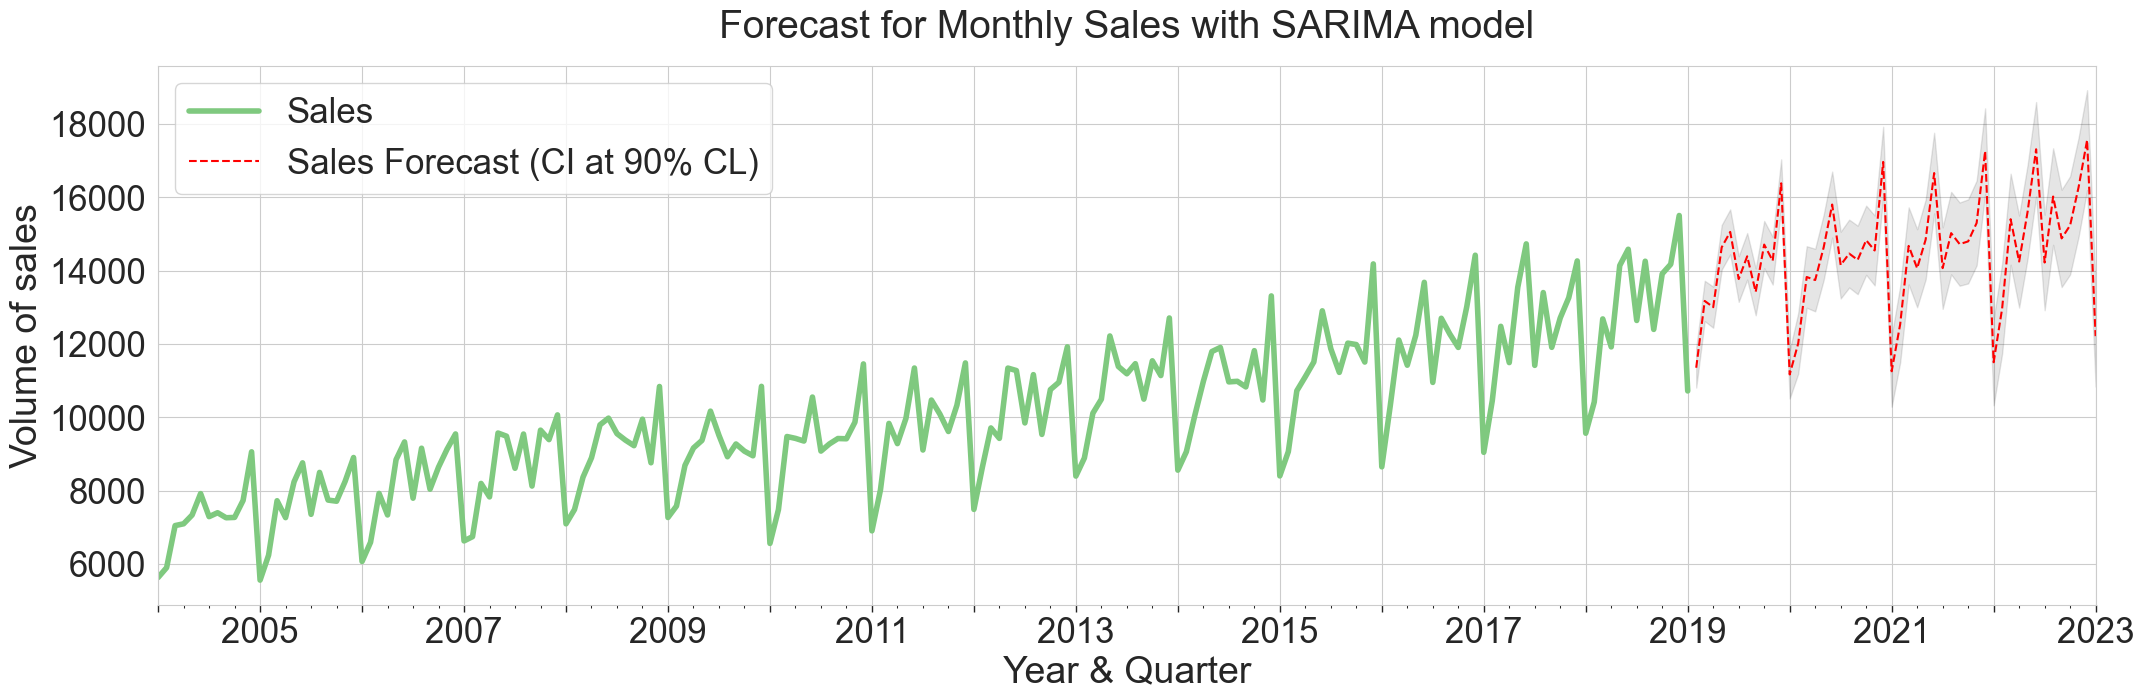

In [92]:
# Plot the data (here we are sub-setting it to get a better look at the forecasts)
ax = df[df.index.year>=2004]["Sales"].plot(legend =True, grid = True, figsize =(25,7), fontsize = 25, colormap = 'Accent', linestyle='-', linewidth = 4)

# Plot 4-years sales forecast:
fcast['mean'].rename('Sales Forecast (CI at 90% CL)').plot(ax=ax, style='r--')

# Plot 95% CL band:
ax.fill_between(fcast.index, fcast['mean_ci_lower'], fcast['mean_ci_upper'], color='k', alpha=0.1); #here alpha is transparency

#Configure x and y labels:
setup_ticks(ax)
plt.ylabel('Volume of sales', fontsize = 27)
plt.xlabel('Year & Quarter', fontsize = 27)
plt.title('Forecast for Monthly Sales with SARIMA model', fontsize = 28, pad=20)
plt.legend(loc='upper left', fontsize = 25)
plt.xticks(rotation=0)
ax.autoscale(enable=True, axis='x', tight=True)

#### Summary 9 (FINAL):

* ARIMA model does a nice job forecasting:
    - It predicts trend and seasonality.
    - It predicts an increasing volatility with time.
    - Confindece intervals increases with time, as should be.

*Prediction is better than simple forecasting methods:
    + Average method: future is the mean of timeseries.
    + Naive method: future is the last observation.
    + Seasonal naive method: future is x_t-T, where T = 12 months (does not capture trend).
    + Drift method: linear trend (does not capture seasonality).

#### To-do's:

* Study and compare with exponential smoothing methods (ETS).
    - Complementary to ARIMA, could be better in some cases.

* Use polynomial regression.
    - According to literature (and my short experience), this is a bad idea, forecast becomes non-sense!

* Use more advanced classical methods.
    - Migrate to R.

* Cross-validation:
    - For ordered data, it is not clear to me if shuffling training sets is a good idea.
    - Even if I do, that is relatively simple, I don't know how to combine or average results of fitted ARIMA models.
        + Perhaps take the mean of coefficients, but not sure how to recover x_t from there.
    - Some literature to read and try:
        + https://www.statsmodels.org/dev/examples/notebooks/generated/statespace_forecasting.html#Cross-validation (Cross-validation is recursively adding a testing point and retrain for predicting the next testing point, and compare MSE vs. not refitting)
        + https://www.sciencedirect.com/science/article/abs/pii/S0020025511006773?via%3Dihub
        + https://www.kaggle.com/code/taufikadi/seasonal-arima-with-cross-validation/notebook

* More machine learning:
    -  Of course, we use tons of linear regression and beyond (likelihood maximization) for this project. That is a lot of automatization for minimization, a.k.a. machine learning.
    - I think we can do better:
        + **Use lags as inputs to NN** to identify linear, (several!) seasonal and non-linear patterns. Does not seem trivial how to evaluate confidence intervals.
        + Use not only historical data, but external variables (wars, inflation, competition, new laws, etc.) that can directly or indirectly affect the timeseries. These are know as 'Dinamyc regression models' (that I have to study). These data can be fed to the NN.
        + **Just need more time to learn and code!!!**